# Utilities

## Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
import re, string, joblib, umap, time, pickle
import numpy as np
from collections import Counter

# Natural language processing
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
from nltk.corpus import stopwords
stop_words = set(stopwords.words('english'))

# Data science
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

# Visualization
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import plotly.express as px

# Hierarchical clustering
from fastcluster import linkage
from scipy.cluster.hierarchy import dendrogram, fcluster
from scipy.spatial.distance import pdist

# Words cloud
from wordcloud import WordCloud

## Functions

In [2]:
# Text preprocessing
def preprocess_text(text, words2remove):
    text = text.lower()                                                  # Lower case
    text = re.sub(r'[^a-z\s]', ' ', text)                                # Remove numbers and special characteres
    # split(r'\s+') is the same as word_tokenize()
    # if the text doesn´t have special characters
    # text = text.split(r'\s+')                                          # Remove multiple spaces, convert to list
    tokens = word_tokenize(text)                                         # Tokenization
    tokens = [word for word in tokens if word not in stop_words]         # Remove stopwords
    tokens = [word for word in tokens if word not in string.punctuation] # Remove punctuation
    tokens = [word for word in tokens if word not in words2remove]       # Remove words from custom list
    tokens = [lemmatizer.lemmatize(word) for word in tokens]             # Lemmatization
    return ' '.join(tokens)

# Word clouds for given string
def word_cloud(text):
    w = 10
    h = 5
    word_freq = Counter(text.split(' '))
    wordcloud = WordCloud(width=w * 100, height=h * 100,
                           background_color='white',
                           stopwords=None,
                           min_font_size=10).generate_from_frequencies(word_freq)
    plt.figure(figsize=(w, h), facecolor=None)
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.tight_layout(pad=0)
    plt.show()

# Load data

In [3]:
data = pd.read_csv('../data/input/api/data_filtered.csv')
data.shape

(4323, 7)

In [4]:
df = pd.read_csv('../data/input/api/data_cleaned.csv')
df.shape

(700, 4)

In [5]:
df_vectorized = pd.read_csv('../data/output/df_vectorized.csv')
X = df_vectorized.values
X.shape

(700, 5953)

In [6]:
words2remove = []

In [7]:
vectorizer = joblib.load('../models/vectorizer.pkl')
words = vectorizer.get_feature_names_out()

Dimensionality reduction

Keep 95% of explained variance

In [8]:
# explained_variance_ratio_goal = 0.8
# pca = PCA(n_components=explained_variance_ratio_goal)
# pca.fit(df_vectorized)
# n_components = pca.n_components_
# n_components

In [9]:
X_original = X.copy()
df_vectorized_original = df_vectorized.copy()

# # X = PCA(n_components=n_components).fit_transform(X) # Specify number of components
# X = pca.transform(X) # Use fitted PCA with 95% of explained variance
# df_vectorized = pd.DataFrame(X)

# # Normalize
# X = X / np.linalg.norm(X, axis=1, keepdims=True)
# df_vectorized = pd.DataFrame(X)

In [10]:
X_original.shape

(700, 5953)

# KNN search

In [11]:
n_neighbors = 100
knn = NearestNeighbors(n_neighbors=n_neighbors, metric='cosine', algorithm='brute').fit(X)

# Query text

# query_text = "reinforcement learning control modular multilevel matrix converter"
# query_text = "reinforcement learning control modular power converter"
# query_text = "physics informed reinforcement learning"
# query_text = "reinforcement learning"
query_text = "The artificial intelligence, deep learning, imitation learning, reinforcement learning, and neural networks in power converters."
# query_text = "Control strategy, closed loop control, nested control, submodules, capacitor voltage, circulating currents, common mode voltage, voltage control, current control, energy control, power control, balancing, model predictive control, proportional integral controller, multi input multi output, modeling, total energy balance, cluster capacitor energy balance, intercluster energy balance, low frequency oscillation mitigation."
print(query_text)

# Preprocessing
query_text = [preprocess_text(query_text, words2remove)]
print(query_text)

# Vectorize
query_text_vec = vectorizer.transform(query_text).toarray()

# Dimensionality reduction
# query_text_vec = pca.transform(query_text_vec)

print(query_text_vec)

# Calculate KNNs
knn_distances, knn_idxs = knn.kneighbors(query_text_vec.reshape(1, -1))

for i, knn_idx in enumerate(knn_idxs[0]):
    print(i)
    print(knn_idx)
    display(f"Neighbor {i+1}:")
    display(f"Title: {data['title'][knn_idx]}")
    display(f"Abstract: {data['abstract'][knn_idx]}")
    display(f"Abstract: {data['html_url'][knn_idx]}")    
    print("-"*40)

The artificial intelligence, deep learning, imitation learning, reinforcement learning, and neural networks in power converters.
['artificial intelligence deep learning imitation learning reinforcement learning neural network power converter']
[[0. 0. 0. ... 0. 0. 0.]]
0
512


'Neighbor 1:'

'Title: a novel hybrid multilevel dc dc converter employing trapezoidal modulation'

'Abstract: this article presents a new hybrid multilevel converter for medium voltage dc dc interconnection the structure of the topology is a hybrid of two level converter and the modular multilevel converter mmc the proposed converter provides three phase trapezoidal output voltages with a controlled slope while using only a single mmc leg therefore using fewer submodules and sensors and with its feature of low energy storage requirement esr the overall size of the converter reduces the front to front configuration of the proposed converter provides the desired voltage matching grounding flexibility and dc fault blocking capability moreover the phase leg switches and the bidirectional switches of the converter are operated in the soft switching mode reducing the converter losses a detailed mathematical analysis is presented to substantiate the low esr and losses of the proposed converter the performance evaluation of the proposed dc dc converter is carried out in pscad emtdc and anal

'Abstract: https://ieeexplore.ieee.org/document/10160141/'

...

'Neighbor 100:'

'Title: a sensorless control method for capacitor voltage balance and circulating current suppression of modular multilevel converter'

'Abstract: there are several problems in the modular multilevel converter mmc such as the appearance of circulating current capacitor voltage unbalance and the requirement for a high number of sensors all these problems will decrease the reliability and raise the cost uncertainty of using mmc solutions as a result a sensorless control method is proposed in this paper which targets to improve the performances of mmc in respect to the above mentioned disadvantages to decrease the cost and simplify the physical implementation a state observer is proposed and designed to estimate both the capacitor voltages and the circulating currents in order to replace the high numbers of sensors furthermore a control method combining the circulating current suppression and the capacitor voltage balancing is conducted based on the proposed state observer it is concluded that the proposed state observer and control method can easily be implemented and its effectiveness are verified by some simulation res

'Abstract: https://ieeexplore.ieee.org/document/7310553/'

----------------------------------------


In [12]:
# import json

# # Save the index to a JSON file
# with open('../data/output/knn_indices.json', 'w') as f:
#     json.dump(knn_idxs[0].tolist(), f)

# Dimensionality reduction

### PCA

In [13]:
# # PCA 2D
# X_pca_2d = PCA(n_components=2).fit_transform(df_vectorized)
# df['pca2d_1'] = X_pca_2d[:, 0]
# df['pca2d_2'] = X_pca_2d[:, 1]

# # PCA 3D
# X_pca_3d = PCA(n_components=3).fit_transform(df_vectorized)
# df['pca3d_1'] = X_pca_3d[:, 0]
# df['pca3d_2'] = X_pca_3d[:, 1]
# df['pca3d_3'] = X_pca_3d[:, 2]

# # Graficar
# colors = np.ones(len(df))  # Color base
# colors_knn = np.zeros(len(df))  # Color para los KNN
# colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

# fig = make_subplots(rows=1, cols=2, subplot_titles=("PCA 2D", "PCA 3D"), 
#                     specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# # Puntos normales (fondo)
# fig.add_trace(
#     go.Scatter(x=df['pca2d_1'], y=df['pca2d_2'], mode='markers',
#                marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                text=data['title'],
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos resaltados (delante)
# fig.add_trace(
#     go.Scatter(x=df.loc[knn_idxs[0], 'pca2d_1'], 
#                y=df.loc[knn_idxs[0], 'pca2d_2'], 
#                mode='markers',
#                marker=dict(color='red', size=5, opacity=1), 
#                text=data.loc[knn_idxs[0], 'title'], 
#                hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
#     row=1, col=1)

# # Puntos normales en 3D (fondo)
# fig.add_trace(
#     go.Scatter3d(x=df['pca3d_1'], y=df['pca3d_2'], z=df['pca3d_3'], mode='markers',
#                  marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
#                  text=data['title'],
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# # Puntos resaltados en 3D (delante)
# fig.add_trace(
#     go.Scatter3d(x=df.loc[knn_idxs[0], 'pca3d_1'], 
#                  y=df.loc[knn_idxs[0], 'pca3d_2'], 
#                  z=df.loc[knn_idxs[0], 'pca3d_3'], 
#                  mode='markers',
#                  marker=dict(color='red', size=5, opacity=1), 
#                  text=data.loc[knn_idxs[0], 'title'], 
#                  hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
#     row=1, col=2)

# fig.update_layout(height=600, width=1200, title_text="PCA 2D y 3D", showlegend=False)
# fig.show()

### UMAP

In [14]:
# n_neighbors = 200
# n_neighbors = int(len(df) / k)

# n_neighbors = 200
n_neighbors = 50 # 6.5x minutos, resultado: vision mas global, no se distinguen tanto los clusters
# n_neighbors = 20 # 2.5x minutos, resultado: no se distinguen los clusters
# n_neighbors = 10 # 1.5x minutos, resultado: puntos muy juntos, se distinguen los clusters
# n_neighbors = 5 # x minutos, resultado: se distinguen bien los clusters, se ven un poco desconectados

min_dist = 0

# UMAP 2D
reducer_2d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=2, random_state=0, metric='cosine')
embedding_2d = reducer_2d.fit_transform(df_vectorized)
df['umap2d_1'] = embedding_2d[:, 0]
df['umap2d_2'] = embedding_2d[:, 1]

# UMAP 3D
reducer_3d = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, n_components=3, random_state=0, metric='cosine')
embedding_3d = reducer_3d.fit_transform(df_vectorized)
df['umap3d_1'] = embedding_3d[:, 0]
df['umap3d_2'] = embedding_3d[:, 1]
df['umap3d_3'] = embedding_3d[:, 2]

# Graficar
colors = np.ones(len(df))  # Color base
colors_knn = np.zeros(len(df))  # Color para los KNN
colors_knn[knn_idxs[0]] = 1  # Resaltar los KNN

fig = make_subplots(rows=1, cols=2, subplot_titles=("UMAP 2D", "UMAP 3D"), 
                    specs=[[{"type": "scatter"}, {"type": "scatter3d"}]])

# Puntos normales (fondo)
fig.add_trace(
    go.Scatter(x=df['umap2d_1'], y=df['umap2d_2'], mode='markers',
               marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
               text=data['title'],
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos resaltados (delante)
fig.add_trace(
    go.Scatter(x=df.loc[knn_idxs[0], 'umap2d_1'], 
               y=df.loc[knn_idxs[0], 'umap2d_2'], 
               mode='markers',
               marker=dict(color='red', size=5, opacity=1), 
               text=data.loc[knn_idxs[0], 'title'], 
               hovertemplate="Titulo: %{text}<br>x: %{x}<br>y: %{y}<extra></extra>"),
    row=1, col=1)

# Puntos normales en 3D (fondo)
fig.add_trace(
    go.Scatter3d(x=df['umap3d_1'], y=df['umap3d_2'], z=df['umap3d_3'], mode='markers',
                 marker=dict(color=colors, colorscale='Viridis', size=3, opacity=0.7), 
                 text=data['title'],
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

# Puntos resaltados en 3D (delante)
fig.add_trace(
    go.Scatter3d(x=df.loc[knn_idxs[0], 'umap3d_1'],
                 y=df.loc[knn_idxs[0], 'umap3d_2'],
                 z=df.loc[knn_idxs[0], 'umap3d_3'],
                 mode='markers',
                 marker=dict(color='red', size=5, opacity=1), 
                 text=data.loc[knn_idxs[0], 'title'], 
                 hovertemplate="Cluster: %{text}<br>x: %{x}<br>y: %{y}<br>z: %{z}<extra></extra>"),
    row=1, col=2)

fig.update_layout(height=600, width=1200, title_text="UMAP 2D y 3D", showlegend=False)
fig.show()

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## Plot KNN

In [15]:
reduced_zero = reducer_2d.transform(np.zeros(df_vectorized.shape[1]).reshape(1, -1))
reduced_knn = reducer_2d.transform(df_vectorized.iloc[knn_idxs[0]])
reduced_query = reducer_2d.transform(query_text_vec)

knn_distances = knn_distances.flatten()
reduced_knn.shape, reduced_query.shape, knn_distances.shape, reduced_zero

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

f:\PabloJimenez\TESIS\SOTA\.venv\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



((100, 2), (1, 2), (100,), array([[10.140699,  6.61363 ]], dtype=float32))

In [16]:
knn_distances = knn_distances[::-1]

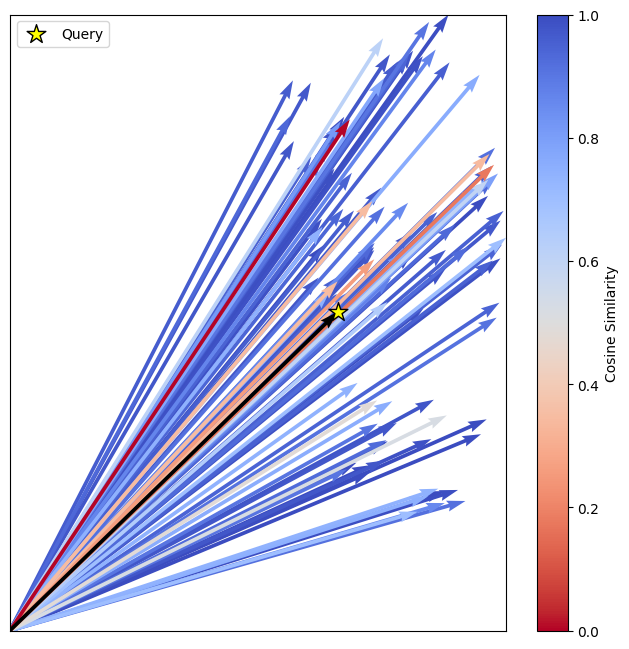

In [17]:
# Asegúrate de que las distancias estén normalizadas entre 0 y 1
exp = 1
knn_distances_normalized = (knn_distances**exp - min(knn_distances**exp)) / (max(knn_distances**exp) - min(knn_distances**exp))

# Graficar
plt.figure(figsize=(8, 8))

# Crear un mapa de colores para las distancias normalizadas
norm = plt.Normalize(vmin=0, vmax=1)  # Normalización de las distancias
sm = plt.cm.ScalarMappable(cmap="coolwarm_r", norm=norm)  # Invertir el colormap con "coolwarm_r"
sm.set_array([])  # Necesario para que la barra de colores funcione

# 2. Graficar los vectores de los vecinos más cercanos (KNN)
for i in range(reduced_knn.shape[0]):
    knn_point = reduced_knn[i]
    color = sm.to_rgba(knn_distances_normalized[i])  # Obtener el color correspondiente a la distancia
    plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], knn_point[0], knn_point[1], angles='xy', scale_units='xy', scale=1, color=color)

# 1. Graficar el vector de consulta (query vector)
query_point = reduced_query[0]
plt.quiver(reduced_zero[0, 0], reduced_zero[0, 1], query_point[0], query_point[1], angles='xy', scale_units='xy', scale=1, color='black')
# Añadir una estrella para el vector de consulta (usamos plt.scatter)
plt.scatter(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 1]+query_point[1], color='yellow', s=200, marker='*', label='Query', edgecolors='black')

# Configuración del gráfico
# plt.gca().set_aspect('equal', adjustable='box')
# plt.title('Query Vector and KNN Vectors')
plt.autoscale(True)
# plt.xlabel('umap2d_1')
# plt.ylabel('umap2d_2')
plt.xticks([])
plt.yticks([])
plt.xlim([min(reduced_zero[0, 0], reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].min()), max(reduced_zero[0, 0]+query_point[0], reduced_zero[0, 0]+reduced_knn[:,0].max())])
plt.ylim([min(reduced_zero[0, 1], reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].min()), max(reduced_zero[0, 1]+query_point[1], reduced_zero[0, 1]+reduced_knn[:,1].max())])
plt.legend()
plt.colorbar(sm, label='Cosine Similarity', ax=plt.gca())
plt.savefig('../data/output/knn.pdf', format='pdf')
plt.show()


# Clustering

## Hierarchical

In [18]:
# methods = ['single', 'complete', 'average', 'weighted', 'centroid', 'ward']
# metrics = ['braycurtis', 'canberra', 'chebyshev', 'cityblock', 'correlation', 'cosine', 'dice', 'euclidean', 'hamming', 'jaccard', 'jensenshannon', 'kulczynski1', 'mahalanobis', 'matching', 'minkowski', 'rogerstanimoto', 'russellrao', 'seuclidean', 'sokalmichener', 'sokalsneath', 'sqeuclidean', 'yule']

methods = ['average', 'complete', 'weighted', 'ward']
metrics = ['cosine', 'jensenshannon', 'correlation']

method = 'ward'
metric = 'cosine'

In [19]:
# Create hierarchical clustering with provided distance matrix
Z = linkage(X, method=method, metric=metric)

# Save clustering
joblib.dump(Z, '../data/output/hierarchical_cluster_Z.joblib')

['../data/output/hierarchical_cluster_Z.joblib']

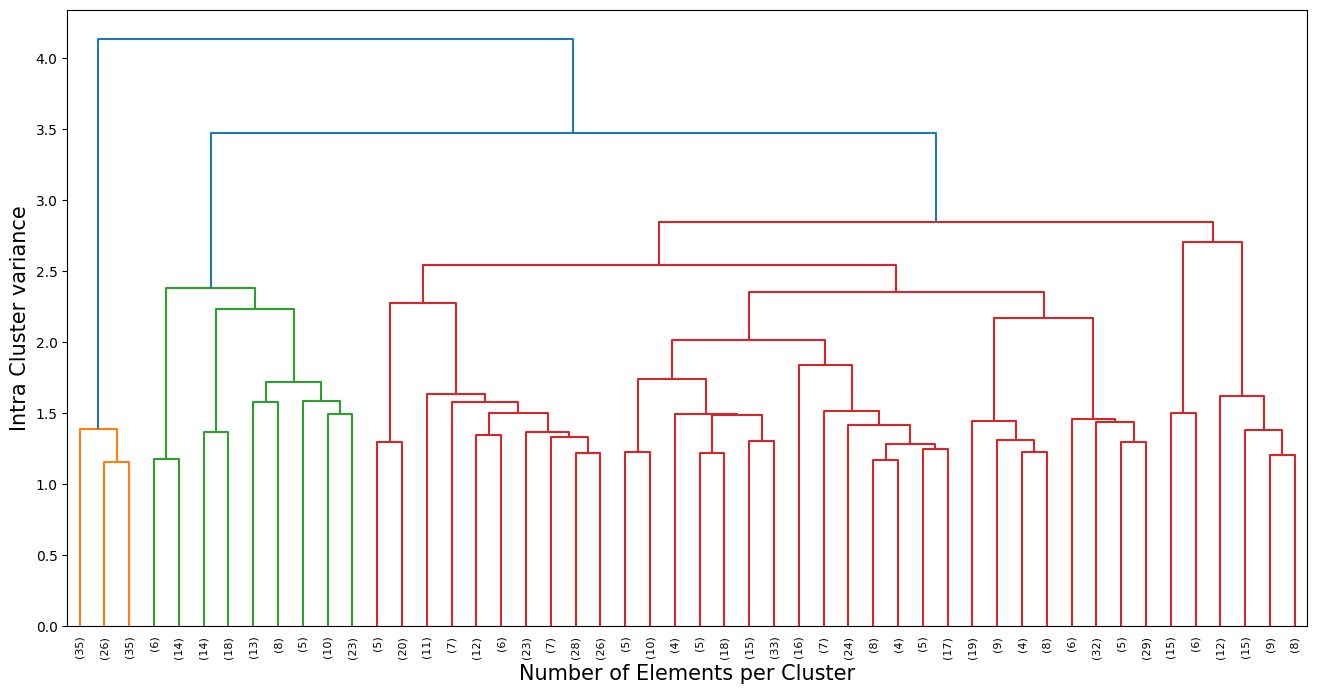

In [20]:
# Load hierarchical clustering
Z = joblib.load('../data/output/hierarchical_cluster_Z.joblib')

# Plot
plt.figure(figsize=(16, 8))
# plt.title("Hierarchical clustering dendrogram")
# dendrogram(Z, truncate_mode='lastp', p=50, leaf_rotation=90, color_threshold=4.96787729660)
dendrogram(Z, truncate_mode='lastp', p=50, leaf_rotation=90, color_threshold=3.3553076382448)
plt.ylabel('Intra Cluster variance', size=15)
plt.xlabel('Number of Elements per Cluster', size=15)
plt.savefig('../data/output/dendrogram.pdf', format='pdf')
plt.show()

In [21]:
# Extract threshold distances for each number of clusters
def get_threshold_distances(Z, k):
    # Extract distances from linkage matrix Z (third column)
    distances = np.sort(Z[:, 2])
    
    # La distancia umbral es la (n-k)-ésima distancia en el dendrograma
    n = Z.shape[0] + 1
    if k >= n:
        return 0  # Si k es igual o mayor al número de muestras, la distancia es mínima
    
    threshold_distance = distances[-(k-1)]
    return threshold_distance

# Rango de clusters deseado
cluster_range = range(3, 51)

# Diccionario para almacenar las distancias umbrales para cada número de clusters
threshold_distances = {k: get_threshold_distances(Z, k) for k in cluster_range}

# Mostrar las distancias umbrales para cada número de clusters
display(threshold_distances)


{3: 3.4737721990395074,
 4: 2.8423838531213774,
 5: 2.702689546716145,
 6: 2.541511177212329,
 7: 2.3793462011630084,
 8: 2.351063788677078,
 9: 2.2756319157426756,
 10: 2.2329681100741623,
 11: 2.16582560403567,
 12: 2.013915062036468,
 13: 1.8358196886684948,
 14: 1.7391303208608448,
 15: 1.7172703467704686,
 16: 1.6346964982412993,
 17: 1.6172764773425787,
 18: 1.5838594452559163,
 19: 1.5776136108243295,
 20: 1.5736616943480368,
 21: 1.5156384519217996,
 22: 1.4963476885684175,
 23: 1.496126242933602,
 24: 1.4923018579661367,
 25: 1.4908922502916984,
 26: 1.4836288393424837,
 27: 1.4535295609295529,
 28: 1.4452570580090986,
 29: 1.4362568272108172,
 30: 1.4121842020928441,
 31: 1.3827757038196267,
 32: 1.381376057261214,
 33: 1.366793200850931,
 34: 1.3620319352071675,
 35: 1.3459192844965966,
 36: 1.3282974593931507,
 37: 1.3052200266928893,
 38: 1.3039127897594778,
 39: 1.2967677145023637,
 40: 1.2964020592588144,
 41: 1.2807617944226506,
 42: 1.2484121733577425,
 43: 1.221387982

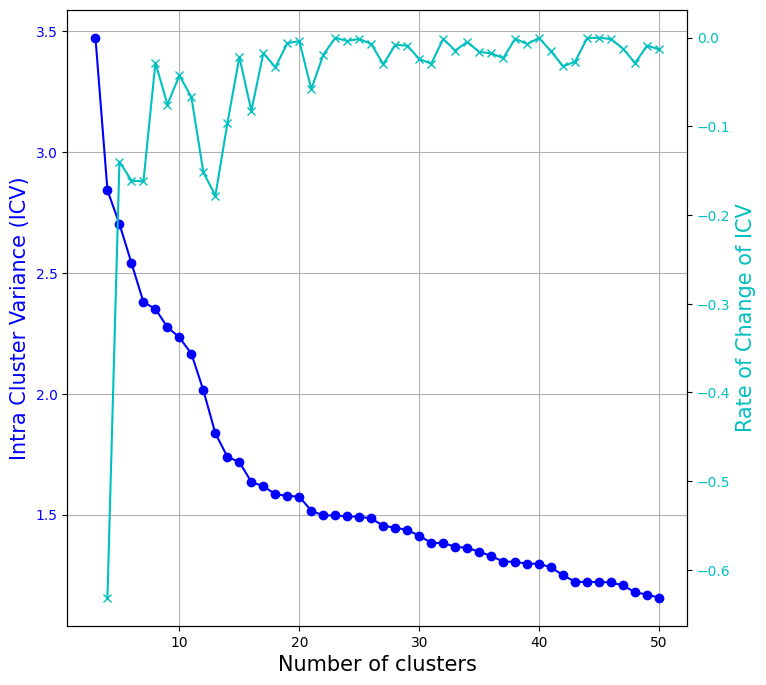

In [22]:
k_range = np.array(list(threshold_distances.keys()))
distances = np.array(list(threshold_distances.values()))
distances_dff = np.diff(distances)

# Create figure
fig, ax1 = plt.subplots(figsize=(8, 8))

# Plot threshold distances
ax1.plot(k_range, distances, marker='o', color='b', label='Threshold Distance')
ax1.set_xlabel('Number of clusters', size=15)
ax1.set_ylabel('Intra Cluster Variance (ICV)', color='b', size=15)
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True)

# Plot rate of change of threshold distances
ax2 = ax1.twinx()
ax2.plot(k_range[1:], distances_dff, marker='x', color='c', label='Rate of Change of Threshold Distance')
ax2.set_ylabel('Rate of Change of ICV', color='c', size=15)
ax2.tick_params(axis='y', labelcolor='c')

# Show plot
# plt.title('Threshold Distance and Rate of Change')
plt.savefig('../data/output/elbow_method_hierarchical_clustering.pdf', format='pdf')
plt.show()

In [23]:
# # Tune threshold for level selection for hierarchical conceptual map
# k_list_concpetual_map = k_range[np.where(distances_dff < -0.5)]
# k_list_concpetual_map

In [24]:
# df_cluster = pd.DataFrame()

# df_cluster['clusters_1'] = 0

# for k in k_list_concpetual_map:
#     clusters_HC = fcluster(Z, k, criterion='maxclust') - 1
#     df_cluster[f'clusters_{k}'] = clusters_HC

# df_cluster['clusters_1'] = 0

# df_cluster

In [25]:
# for col_idx, n_clusters in enumerate(df_cluster.columns):
#     for cluster in df_cluster[n_clusters].sort_values().unique():

#         df_topic = df_vectorized_original[df_cluster[n_clusters] == cluster]
#         centroid_words = summarize(df_topic, 5)
#         print(f'Cluster {cluster} ({df_topic.shape[0]}): {centroid_words}')

#         print(f' |---- Cluster {0}')
#     print('-'*100)

Elegir cantidad de tópicos

In [26]:
k = 5
clusters = list(range(k))
print(clusters)

[0, 1, 2, 3, 4]


In [27]:
# Asignar el cluster correspondiente
df['cluster_HC'] = fcluster(Z, k, criterion='maxclust') - 1
print(sorted(df['cluster_HC'].unique()))
df["cluster_HC"].value_counts()

[0, 1, 2, 3, 4]


cluster_HC
2    428
1    111
0     96
4     44
3     21
Name: count, dtype: int64

## Kmeans

### Metodo del codo

In [28]:
# # Listas para almacenar la inercia y el Silhouette Score de cada k
# inertia = []
# silhouette_scores = []

# # Rango de k para probar
# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Calcular la inercia y el Silhouette Score para cada valor de k
# for k_value in k_range:
#     print(f"Comenzando KMeans para k={k_value}")
#     tic = time.time()

#     kmeans = KMeans(n_clusters=k_value, random_state=0, n_init=100, init='k-means++', max_iter=100)
#     kmeans.fit(X)
    
#     # Almacenar la inercia
#     inertia.append(kmeans.inertia_)
    
#     # Calcular el Silhouette Score y almacenarlo
#     score = silhouette_score(X, kmeans.labels_)
#     silhouette_scores.append(score)
    
                                
#     toc = time.time()
#     print(f"Completado en {toc - tic:.2f} segundos\n")

# # Guardar
# with open('data/output/kmeans_metrics.pkl', 'wb') as f:
#     pickle.dump({'inertia': inertia, 'silhouette_scores': silhouette_scores}, f)

# k_range = range(10, 51)  # Puedes cambiar el rango de 1 a 10, o más según necesites

# # Cargar
# with open('data/output/kmeans_metrics.pkl', 'rb') as f:
#     metrics = pickle.load(f)
# inertia = metrics['inertia']
# silhouette_scores = metrics['silhouette_scores']

# # Calcular la tasa de cambio para la inercia y el Silhouette Score
# delta_inertia = np.diff(inertia)
# delta_silhouette = np.diff(silhouette_scores)

# # Crear una figura con dos subgráficos (lado a lado)
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# # Graficar la inercia en el primer subgráfico (izquierda)
# ax1.plot(k_range, inertia, marker='o', color='b', label='Inercia')
# ax1.set_xlabel('Número de clusters (k)')
# ax1.set_ylabel('Inercia', color='b')
# ax1.tick_params(axis='y', labelcolor='b')

# # Graficar la tasa de cambio de la inercia en el eje y derecho
# ax1_twin = ax1.twinx()
# ax1_twin.plot(k_range[1:], delta_inertia, marker='x', color='c', label='Tasa de cambio de Inercia')
# ax1_twin.set_ylabel('Tasa de cambio de Inercia', color='c')
# ax1_twin.tick_params(axis='y', labelcolor='c')

# # Título y leyenda para el primer gráfico
# ax1.set_title('Inercia y Tasa de Cambio de Inercia')
# # ax1.legend(loc='best')

# # Graficar el Silhouette Score en el segundo subgráfico (derecha)
# ax2.plot(k_range, silhouette_scores, marker='o', color='g', label='Silhouette Score')
# ax2.set_xlabel('Número de clusters (k)')
# ax2.set_ylabel('Silhouette Score', color='g')
# ax2.tick_params(axis='y', labelcolor='g')

# # Graficar la tasa de cambio del Silhouette Score en el eje y derecho
# ax2_twin = ax2.twinx()
# ax2_twin.plot(k_range[1:], delta_silhouette, marker='x', color='y', label='Tasa de cambio de Silhouette Score')
# ax2_twin.set_ylabel('Tasa de cambio de Silhouette Score', color='y')
# ax2_twin.tick_params(axis='y', labelcolor='y')

# # Título y leyenda para el segundo gráfico
# ax2.set_title('Silhouette Score y Tasa de Cambio de Silhouette Score')
# # ax2.legend(loc='best')

# # Mostrar el gráfico
# plt.tight_layout()  # Ajusta el espacio entre los subgráficos
# plt.show()

### Clustering final

In [29]:
# kmeans = KMeans(n_clusters=k, random_state=0, n_init=100, init='k-means++', max_iter=100).fit(X)
# df["cluster_KM"] = kmeans.predict(X)

# print(sorted(df['cluster_KM'].unique()))
# df["cluster_KM"].value_counts()

Clasificación de un texto

In [30]:
# predicted_cluster = kmeans.predict(topico_vec)
# print(predicted_cluster)

## Results

In [31]:
# Pintar los KNN del topico consultado
# df.loc[indices_knn[0], "cluster_HC"] = -1
# df.loc[indices_knn[0], "cluster_KM"] = -1

Choose clustering type:
* cluster_HC
* cluster_KM

In [32]:
# Select clsutering method
clustering_method = "cluster_HC"

# Convert clsuter column to categorical type
df[clustering_method] = df[clustering_method].astype('category')

In [33]:
# # PCA

# # Calcular centroides de cada cluster
# centroids = df.groupby(clustering_method)[['pca2d_1', 'pca2d_2']].mean().reset_index()

# # Crear gráfico de dispersión interactivo con leyenda discreta
# fig = px.scatter(
#     df, 
#     x='pca2d_1',
#     y='pca2d_2',
#     size=None,
#     color=clustering_method,  # Usar la columna categórica para el color
#     title='PCA 2D',
#     color_discrete_sequence=px.colors.qualitative.Alphabet,  # Usar una paleta de colores discreta
#     hover_data=[clustering_method, 'title'],  # Agregar el cluster y el título al tooltip
#     hover_name='title',  # Mostrar el título como identificador principal en el tooltip
#     opacity=0.5,
#     category_orders={clustering_method: clusters}
# )

# # Asegurar que la relación de aspecto sea 1:1 tanto en los ejes como en la figura
# fig.update_layout(
#     xaxis=dict(scaleanchor="y"),  # Vincula la escala del eje x con el eje y
#     yaxis=dict(scaleanchor="x"),  # Vincula la escala del eje y con el eje x
#     width=800,  # Establece un tamaño específico para el ancho
#     height=600,  # Establece el mismo tamaño para la altura
#     legend_title_text='Cluster'  # Personalizar el título de la leyenda
# )

# # Personalizar el formato del tooltip
# fig.update_traces(
#     marker=dict(size=5),
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +  # Título en negrita
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +  # Mostrar el cluster (usando customdata)
#                   "<b>X:</b> %{x}<br>" +  # Coordenada X
#                   "<b>Y:</b> %{y}<br>" +  # Coordenada Y
#                   "<extra></extra>"  # Eliminar información adicional no deseada
# )

# # Agregar puntos resaltados en rojo, sin que aparezcan en la leyenda
# fig.add_scatter(
#     x=df.loc[knn_idxs[0], 'pca2d_1'],
#     y=df.loc[knn_idxs[0], 'pca2d_2'],
#     mode='markers',
#     marker=dict(color='red', size=10, line=dict(color='black', width=2)),
#     name='KNNs',
#     showlegend=True,
#     customdata=df.loc[knn_idxs[0], [clustering_method]],  # Asegurar que tengan los mismos datos adicionales
#     hovertext=df.loc[knn_idxs[0], 'title'],  # Usar el título también para estos puntos
#     hovertemplate="<b>Title:</b> %{hovertext}<br>" +
#                   "<b>Cluster:</b> %{customdata[0]}<br>" +
#                   "<b>X:</b> %{x}<br>" +
#                   "<b>Y:</b> %{y}<br>" +
#                   "<extra></extra>"
# )

# # Obtener los colores usados en el gráfico principal
# colors = px.colors.qualitative.Alphabet

# # Crear un diccionario que mapea cada cluster a un color
# cluster_colors = dict(zip(df[clustering_method].cat.categories, colors))

# # Agregar centroides con el color correspondiente de su cluster
# for cluster in centroids[clustering_method]:
#     centroid = centroids[centroids[clustering_method] == cluster]
#     fig.add_scatter(
#         x=centroid['pca2d_1'],
#         y=centroid['pca2d_2'],
#         mode='markers',
#         marker=dict(color=cluster_colors[cluster], size=10, symbol='x', line=dict(color='black', width=2)),
#         name=f'Centroid {cluster}',  # Opcional, si quieres que aparezca en la leyenda
#         showlegend=False
#     )

# # Mostrar el gráfico
# fig.show()

In [34]:
# UMAP

# Calcular centroides de cada cluster
centroids = df.groupby(clustering_method)[['umap2d_1', 'umap2d_2']].mean().reset_index()

# Crear gráfico de dispersión interactivo con leyenda discreta
fig = px.scatter(
    df, 
    x='umap2d_1',
    y='umap2d_2',
    size=None,
    color=clustering_method,  # Usar la columna categórica para el color
    # title='UMAP 2D',
    color_discrete_sequence=px.colors.qualitative.Alphabet,  # Usar una paleta de colores discreta
    hover_data=[clustering_method, 'title'],  # Agregar el cluster y el título al tooltip
    hover_name='title',  # Mostrar el título como identificador principal en el tooltip
    opacity=0.5,
    category_orders={clustering_method: clusters}
)

# Asegurar que la relación de aspecto sea 1:1 tanto en los ejes como en la figura
fig.update_layout(
    xaxis=dict(scaleanchor="y"),  # Vincula la escala del eje x con el eje y
    yaxis=dict(scaleanchor="x"),  # Vincula la escala del eje y con el eje x
    width=800,  # Establece un tamaño específico para el ancho
    height=800,  # Establece el mismo tamaño para la altura
    legend_title_text='Cluster',  # Personalizar el título de la leyenda
    legend_title_font_size=15,
    xaxis_title_font_size=15,
    yaxis_title_font_size=15
)

# Personalizar el formato del tooltip
fig.update_traces(
    marker=dict(size=5),
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +  # Título en negrita
                  "<b>Cluster:</b> %{customdata[0]}<br>" +  # Mostrar el cluster (usando customdata)
                  "<b>X:</b> %{x}<br>" +  # Coordenada X
                  "<b>Y:</b> %{y}<br>" +  # Coordenada Y
                  "<extra></extra>"  # Eliminar información adicional no deseada
)

# Agregar puntos resaltados en rojo, sin que aparezcan en la leyenda
fig.add_scatter(
    x=df.loc[knn_idxs[0], 'umap2d_1'],
    y=df.loc[knn_idxs[0], 'umap2d_2'],
    mode='markers',
    marker=dict(color='red', size=10, line=dict(color='black', width=2)),
    name='KNNs',
    showlegend=True,
    customdata=df.loc[knn_idxs[0], [clustering_method]],  # Asegurar que tengan los mismos datos adicionales
    hovertext=df.loc[knn_idxs[0], 'title'],  # Usar el título también para estos puntos
    hovertemplate="<b>Title:</b> %{hovertext}<br>" +
                  "<b>Cluster:</b> %{customdata[0]}<br>" +
                  "<b>X:</b> %{x}<br>" +
                  "<b>Y:</b> %{y}<br>" +
                  "<extra></extra>"
)

# Obtener los colores usados en el gráfico principal
colors = px.colors.qualitative.Alphabet

# Crear un diccionario que mapea cada cluster a un color
cluster_colors = dict(zip(df[clustering_method].cat.categories, colors))

# Agregar centroides con el color correspondiente de su cluster
for cluster in centroids[clustering_method]:
    centroid = centroids[centroids[clustering_method] == cluster]
    fig.add_scatter(
        x=centroid['umap2d_1'],
        y=centroid['umap2d_2'],
        mode='markers',
        marker=dict(color=cluster_colors[cluster], size=10, symbol='x', line=dict(color='black', width=2)),
        name=f'Centroid {cluster}',  # Opcional, si quieres que aparezca en la leyenda
        showlegend=False
    )

# Save
fig.write_image("../data/output/UMAP.pdf")
# Mostrar el gráfico
fig.show()

C:\Users\Ingeniería Eléctrica\AppData\Local\Temp\ipykernel_3088\328979349.py:4: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



# Summarization
Importantest words by Tf-Idf score

In [35]:
def summarize(df_topic, n_centroid_words):

    # Find centroid
    centroid = df_topic.mean(axis=0)

    # Take the n first words
    centroid_words = ", ".join([words[idx] for idx in centroid.argsort()[::-1][:n_centroid_words]])
    
    # To list, remove duplicated words
    centroid_words = centroid_words.replace(',','').split(' ')
    centroid_words_temp = []
    for word in centroid_words:
        if word not in centroid_words_temp:
            centroid_words_temp.append(word)
    centroid_words = centroid_words_temp
    
    return centroid_words

### Corpus

In [36]:
df_topic = df_vectorized_original.copy()
centroid_words = summarize(df_topic, 10)
print(f'Full corpus: {centroid_words}')

# word_cloud(centroid_words)

Full corpus: ['control', 'voltage', 'current', 'converter', 'energy', 'multilevel', 'power', 'modular', 'model', 'dc']


### Clusters

In [37]:
for cluster in clusters:
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 10)
    print(f'Cluster {cluster}: {", ".join(centroid_words)}')

    # word_cloud(centroid_words)

Cluster 0: predictive, control, model, voltage, current, mpc, converter, multilevel, cost, function
Cluster 1: energy, control, voltage, storage, power, wind, converter, grid, current, system
Cluster 2: control, voltage, current, converter, multilevel, power, capacitor, dc, modular, mmc
Cluster 3: impedance, control, oscillation, loop, frequency, model, stability, outer, voltage, mmc
Cluster 4: matrix, control, converter, branch, current, voltage, multilevel, frequency, modular, energy


# Hierarchical conceptual map

In [38]:
# import networkx as nx

# # Crear el grafo dirigido
# G = nx.DiGraph()

# # Ejemplo de títulos y niveles de clusters
# niveles = {
#     0: [],
#     1: ["Cluster A", "Cluster B", "Cluster C"],
#     2: ["Cluster A1", "Cluster A2", "Cluster B1", "Cluster B2", "Cluster C1"]
# }

# # Conectar los niveles de clusters
# relaciones = [
#     ('\n'.join(centroid_words), "Cluster A"),
#     ('\n'.join(centroid_words), "Cluster B"),
#     ('\n'.join(centroid_words), "Cluster C"),
#     ("Cluster A", "Cluster A1"),
#     ("Cluster A", "Cluster A2"),
#     ("Cluster B", "Cluster B1"),
#     ("Cluster B", "Cluster B2"),
#     ("Cluster C", "Cluster C1")
# ]

# # Agregar nodos y aristas al grafo
# for nivel in niveles.values():
#     G.add_nodes_from(nivel)
# G.add_edges_from(relaciones)

# # Asignar posiciones centradas a los nodos
# pos = {}
# max_width = max(len(nodos) for nodos in niveles.values())

# for nivel, nodos in niveles.items():
#     offset = (max_width - len(nodos)) / 2
#     for i, nodo in enumerate(nodos):
#         pos[nodo] = (i + offset, -nivel)

# # Dibujar el mapa conceptual jerárquico
# plt.figure(figsize=(8, 6))
# nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightblue', font_size=10, font_weight='bold', edge_color='gray')
# plt.title("Mapa Conceptual Jerárquico")
# plt.show()

# Documento representativo
En corpus completo y por clusters

## Centroides

In [39]:
# def encontrar_mas_cercano_al_centroide(df_vectorized, data):
#     centroide = df_vectorized.mean(axis=0)
#     distancias = euclidean_distances(df_vectorized, [centroide])
#     indice_mas_cercano = np.argmin(distancias)
#     texto_mas_cercano = data.iloc[indice_mas_cercano]['abstract']
#     titulo = data.iloc[indice_mas_cercano]['title']
#     return titulo, texto_mas_cercano

### Corpus

In [40]:
# titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(df_vectorized, data)
# display(f"Texto mas representativo del corpus:")
# display(f"Título: {titulo}")
# display(f"Abstract: {texto_mas_cercano}")

### Clusters

In [41]:
# for cluster in clusters:
#     cluster_data_vectorized = df_vectorized.loc[(df[clustering_method] == cluster).values]
#     cluster_data = data[df[clustering_method] == cluster]
#     titulo, texto_mas_cercano = encontrar_mas_cercano_al_centroide(cluster_data_vectorized, cluster_data)
#     display(f"Cluster {cluster}: Texto mas cercano al centroide")
#     display(f"Título: {titulo}")
#     display(f"Abstract: {texto_mas_cercano}")

## Puntaje Tfidf
Le llamaremos representante al abstract que tenga una mayor cantidad de frecuencia acumulada de palabras del tfid vectorizer, ya que eso implica una mayor participación (profundizar).

Disclaimer: Tenía razón en dudad del método. esto en verdad lo k hace es elegir al que tiene mayor interaccion entre palabras, es decir, el abstract mas complejo.

### Corpus

In [42]:
abstract00 = df_vectorized.sum(axis=1).sort_values(ascending=False).index[0]
display("Texto más representativo del corpus:")
display(f"Título: {data['title'].iloc[abstract00]}")
display(f"Abstract: {data['abstract'].iloc[abstract00]}")

'Texto más representativo del corpus:'

'Título: a power balancing strategy in a pv based modular multilevel converter during mismatched power generation'

'Abstract: in this article we focus on the power balancing strategy in a modular multilevel converter mmc for a large scale photovoltaic pv system large scale pv based mmc suffers from leg leg and arm arm power mismatch issues leading to unbalanced power injection into ac grid to inject balanced power into the ac grid this article proposes a novel control technique which minimizes the circulating current in the converter a novel two fundamental frequency zero sequence voltages injection technique is proposed for a leg leg horizontal power mismatch by which the dc circulating current from the mmc legs can be minimized significantly simultaneously an independent arm power control technique is proposed for an arm arm vertical power mismatch thereby minimizing the ac circulating current with the proposed control strategies overcurrent and subsequent losses in the converter due to circulating current can be reduced both horizontal and vertical power mismatch problems are theoretically analy

### Clusters

In [43]:
for cluster in clusters:
    abstract00 = df_vectorized.loc[(df[clustering_method] == cluster).values].sum(axis=1).sort_values(ascending=False).index[0]
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 10)
    display(f"Cluster {cluster}: {centroid_words}")
    display(f"Título: {data['title'].iloc[abstract00]}")
    display(f"Abstract: {data['abstract'].iloc[abstract00]}")

"Cluster 0: ['predictive', 'control', 'model', 'voltage', 'current', 'mpc', 'converter', 'multilevel', 'cost', 'function']"

'Título: a novel method based on self power supply control for balancing capacitor static voltage in mmc'

'Abstract: the modular multilevel converter is one of the most attractive converter topologies for high voltage dc transmission systems but it needs at least 10 min during the system uncontrolled precharge stage to verify the stability and reliability of submodules sms making the capacitor static voltage balancing a key issue this paper proposes a novel method based on self power supply control for balancing capacitor static voltage because of the influence of self power supplies on capacitor voltages the method can keep the capacitor static voltage balanced by controlling the input characteristic of sms self power supplies the control signals of self power supplies have a fixed frequency and duty ratio and they can be determined based on capacitor voltage sorting results and self power supply output support capacitor compared with previous works this method has less computation and it does not rely on igbts and additional complex circuits except for the self power supplies this can sa

"Cluster 1: ['energy', 'control', 'voltage', 'storage', 'power', 'wind', 'converter', 'grid', 'current', 'system']"

'Título: a power balancing strategy in a pv based modular multilevel converter during mismatched power generation'

...

'Título: a power traction converter based on modular multilevel architecture integrated with energy storage devices'

'Abstract: in this paper a power converter based on a modular multilevel topology integrated with energy storage devices for directly supplying of traction motors is discussed the modular multilevel converter mmc is one of the emerging technology for high or medium voltage transformerless power conversion the possibility to directly control the traction motors by means of a dc ac mmc topology using also integrated energy storage systems ess for recovering the kinetic energy is exploited furthermore a simplified mathematical model of the mmc with integrated ess has been developed in order to evaluate the behavior of the traction unit during a typical load cycle the control law of the traction motor integrated with energy storage flow management has been introduced the numerical results reported in the paper permit to confirm the feasibility of the proposed design and control strategy for light travel vehicle'

"Cluster 4: ['matrix', 'control', 'converter', 'branch', 'current', 'voltage', 'multilevel', 'frequency', 'modular', 'energy']"

'Título: a mathematical analysis of y matrix modulation the natural self voltage balancing capability of modular multilevel converter under arbitrary level number'

'Abstract: the modular multilevel converter mmc is a promising topology for high and medium voltage applications for its unique advantages over traditional vsc topologies the sub module voltage balancing issue is one of the most important topics of mmc as the count of output voltage levels increases the balancing control for each submodule gets complex which aggravates control burden of the system to overcome this problem a novel y matrix modulation ymm method has been proposed it achieves submodule voltage balancing without any extra control mechanism by making full use of the natural self voltage balancing characteristic of mmc with minimum arm inductor however an unsolved issue of the emerging ymm is that the rank of the compound matrix of any two adjacent output voltage levels has not been derived theoretically which means a complex rank check algorithm is inevitable when the sub module number is large to fill this theoretical gap a solid mathematical proof is provided in this pape

## Similaridad del coseno

### Corpus

In [44]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def RepresentanteCoseno(matrix_vectors):
    """
    Retorna el índice del texto más representativo del conjunto (más similar al resto).
    
    Parameters:
    - matrix_vectors: matriz (numpy array o pandas DataFrame) donde cada fila es un vector (TF-IDF o embedding)
    
    Returns:
    - Índice del texto más representativo
    """
    # Asegura que sea array de NumPy
    if hasattr(matrix_vectors, 'values'):
        matrix_vectors = matrix_vectors.values

    # Calcular matriz de similitud coseno
    similitudes = cosine_similarity(matrix_vectors)
    
    # Sumar similitudes por fila (suma de cada vector con todos los demás)
    suma_similitudes = np.sum(similitudes, axis=1)
    
    # Retornar índice del vector con mayor similitud total
    return np.argmax(suma_similitudes)


In [45]:
abstract00 = RepresentanteCoseno(df_vectorized)
titulo = data["title"].iloc[abstract00]
abstract_mas_representativo = data["abstract"].iloc[abstract00]

display(f"Texto mas similar a todos los demas en el corpus:")
display(f"Título: {titulo}")
display(f"Abstract: {abstract_mas_representativo}")

'Texto mas similar a todos los demas en el corpus:'

'Título: a broad range of speed control of a permanent magnet synchronous motor driven by a modular multilevel tsbc converter'

'Abstract: this paper provides a theoretical and experimental discussion on a modular multilevel triple star bridge cell converter with focus on mitigating the capacitor voltage fluctuation contained in each bridge cell a new control method proposed in this paper is characterized by properly superimposing both common mode voltage and circulating currents in the whole speed range moreover this paper optimizes the amplitude and frequency of the superimposed common mode voltage on the basis of theoretical analysis thus resulting in minimizing the voltage fluctuation the optimized control method makes both voltage fluctuation and cluster current amplitude smaller than do the existing methods experimental waveforms obtained from a three phase downscaled system using a 370 v 15 kw 75 hz six pole permanent magnet synchronous motor verify good start up performance from a standstill to the rated speed keeping both capacitor voltage and cluster current within acceptable levels'

### Clusters

In [46]:
for cluster in clusters:
    abstract00 = RepresentanteCoseno(df_vectorized.loc[(df[clustering_method] == cluster).values])
    titulo = data["title"].iloc[abstract00]
    abstract_mas_representativo = data["abstract"].iloc[abstract00]
    df_topic = df_vectorized_original[df[clustering_method] == cluster]
    centroid_words = summarize(df_topic, 10)
    display(f"Cluster {cluster}: {centroid_words}")
    display(f"Título: {titulo}")
    display(f"Abstract: {abstract_mas_representativo}")

"Cluster 0: ['predictive', 'control', 'model', 'voltage', 'current', 'mpc', 'converter', 'multilevel', 'cost', 'function']"

'Título: a capacitor voltage balancing method with fundamental sorting frequency for modular multilevel converters under staircase modulation'

'Abstract: a fundamental frequency sorting algorithm with staircase modulation is proposed to balance the floating capacitors for modular multilevel converters the driving pulses are assigned to the submodules at every fundamental period according to their charging capabilities for the capacitors the charging capabilities of the driving pulses can be evaluated by sorting the voltage increments of the capacitors or derived from the symmetrical characteristic of the curve between the voltage increments and the pulse numbers with this method all the power devices switch only once per fundamental period which is suitable for high power applications meanwhile the sorting frequency decreases to the fundamental frequency hence a large number of calculation resources can be saved moreover it does not need to measure the arm currents so that several current sensors can be saved and the communication protocol between the central and local controllers can be simplified at last a three phase simul

"Cluster 1: ['energy', 'control', 'voltage', 'storage', 'power', 'wind', 'converter', 'grid', 'current', 'system']"

'Título: a broad range of speed control of a permanent magnet synchronous motor driven by a modular multilevel tsbc converter'

...

'Título: a 43 level 33 kv 3 phase modular multilevel cascaded converter for direct grid integration of renewable generation systems'

'Abstract: this paper proposed a 43 level 3 phase 33 kv modular multilevel cascaded mmc converter for direct grid integration of renewable generation systems a high frequency magnetic link is considered to generate isolated and balanced multiple dc sources for all of the h bridge inverters of the mmc converter the proposed converter is designed and analyzed taking into account the specified system performance control complexity cost and market availability of the semiconductors the simulation results demonstrate the excellent feature of the proposed medium voltage converter it is expected that the proposed new technology will have great potential for future renewable power plants and smart grid applications'

"Cluster 4: ['matrix', 'control', 'converter', 'branch', 'current', 'voltage', 'multilevel', 'frequency', 'modular', 'energy']"

'Título: a 40 pulse multiphase staggering modular transformer with power quality improvement in multilevel inverter fed medium voltage induction motor drives'

'Abstract: in this article a new configuration of the adjustable speed drive is proposed for the medium voltage industrial induction motor drives imds here a new configuration of a 40 pulse multiphase staggering modular transformer is proposed for power quality improvement in the vector controlled induction motor drive vcimd at the utility end in it the two transformers t1 and t2 are utilized and both have extended delta configured input windings with 9 and 9 phase shift and their secondaries have two sets of five phase ac supplies to achieve a 20 pulse ac dc conversion because of these primary angles these two transformers are reconfigured as a 40 pulse ac dc converter a new cascaded multilevel inverter c mli is proposed at the drive end this c mli is cascading four two level voltage source inverters in a unique manner to get nine levels in its line voltage a modified sinusoidal pulsewidth modulation strategy is utilized which offers very low switching frequency low switching losses e

# Grafo de palabras

## Palabras de un abstract especifico

In [47]:
# # Obtener el texto del dataframe
# texto = df.iloc[1000]["abstract"]

# # Procesar el texto con spaCy
# doc = nlp(texto)

# # Crear grafo dirigido con NetworkX
# G = nx.DiGraph()
# for token in doc:
#     if not token.is_stop and not token.is_punct:
#         G.add_node(token.text)
#     for child in token.children:
#         if not child.is_stop and not child.is_punct:
#             G.add_edge(token.text, child.text)

# # Calcular importancia con PageRank
# pagerank = nx.pagerank(G)

# # Crear el grafo con Graphviz
# dot = Digraph(format="png")
# dot.attr(dpi="300", rankdir="LR", bgcolor="white")

# # Agregar nodos con tamaño basado en PageRank
# max_pr = max(pagerank.values()) if pagerank else 1
# for node, pr in pagerank.items():
#     size = str(int(10 + (pr / max_pr) * 30))  # Tamaño proporcional
#     dot.node(node, fontsize=size, shape="ellipse", style="filled", fillcolor="lightblue")

# # Agregar aristas
# for u, v in G.edges():
#     dot.edge(u, v, color="black", penwidth="1.5")

# # Renderizar el grafo en un archivo temporal
# output_file = "Data/Figuras/grafo"
# dot.render(output_file, format="png", cleanup=True)
# # Mostrar la imagen en Jupyter Notebook
# display(Image(filename=output_file + ".png"))

## Entre clusters